# Reading the splines: KANVAS shape functions vs SHAP explanations on the same tasks

Two ways to explain a GPU-failure model, side by side on the same test tasks. The first is a Kolmogorov-Arnold
additive model (KAAM, the KANVAS model from part 4), whose explanation is the model itself: one curve per feature,
and each prediction is exactly the sum of the curve values. The second is LightGBM explained after the fact with
TreeSHAP. The notebook checks with brute-force Shapley values that the two explanations measure the same thing for
an additive model, compares them feature by feature and task by task, and follows one sharp curve to its source: a
rule that belongs to a single user.

- Data: `kanvas_tasks_1h.parquet` from the dataset [alibaba-gpu-trace-2020](https://www.kaggle.com/datasets/swapnilshukla007/alibaba-gpu-trace-2020), derived from [cluster-trace-gpu-v2020](https://github.com/alibaba/clusterdata/tree/master/cluster-trace-gpu-v2020) (CC BY 4.0, Weng et al., NSDI 2022)
- Run time: 5 to 10 minutes on a Kaggle CPU notebook, no GPU needed
- Part 5 of a five-part series from the KANVAS project. Live app: [kanvas.streamlit.app](https://kanvas.streamlit.app) | Code: [github.com/Swapnil007-Curious/KANVAS](https://github.com/Swapnil007-Curious/KANVAS) | Paper: link to be added

## Contents

1. Setup and the two models
2. For an additive model, SHAP values are the centred curves: an exact check
3. Global importance: do the two explanations rank features alike?
4. Curves against SHAP dependence plots
5. Task by task: how often do the explanations agree?
6. Three tasks explained both ways
7. Following one curve: the one-core rule and user 1
8. What we found, limitations and next steps

## 1. Setup and the two models

Both models see the same stratified 70/15/15 split of tasks, with clipping and scaling fitted on the training part
(as in parts 3 and 4). Each gets a small hyperparameter search on validation ROC-AUC.

In [1]:
import os
import time
import warnings
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Paths. On Kaggle the defaults apply; the two environment variables let the same notebook run elsewhere.
INPUT_ROOT = Path(os.environ.get("KAGGLE_INPUT_ROOT", "/kaggle/input"))
WORKING = Path(os.environ.get("KAGGLE_WORKING", "/kaggle/working"))
WORKING.mkdir(parents=True, exist_ok=True)

# FAST = True runs a smaller version for a quick check on a small machine. Kaggle runs use the full data.
FAST = os.environ.get("KANVAS_FAST", "0") == "1"
SEED = 42  # one seed for every random choice in the notebook

# Okabe-Ito colours, chosen so the series stay distinct for the common forms of colour blindness.
BLUE, ORANGE, GREEN, VERMILLION, PURPLE, SKY, YELLOW, BLACK = (
    "#0072B2", "#E69F00", "#009E73", "#D55E00", "#CC79A7", "#56B4E9", "#F0E442", "#000000")
PALETTE = [BLUE, ORANGE, GREEN, VERMILLION, PURPLE, SKY, BLACK]
SEQUENTIAL_CMAP = "cividis"  # one perceptually uniform ramp for heatmaps

mpl.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 100, "font.size": 11, "axes.titlesize": 13, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3,
    "axes.prop_cycle": mpl.cycler(color=PALETTE), "legend.frameon": False,
})
np.random.seed(SEED)
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)


def find_data_dir(required, root=INPUT_ROOT, max_depth=4):
    """Return the first folder under ``root`` that contains every file in ``required``.

    Kaggle mounts attached datasets under /kaggle/input, and the exact sub-path has changed over the
    years, so the notebook searches for the files instead of hard-coding one layout.
    """
    root = Path(root)
    for dirpath, dirnames, filenames in os.walk(root):
        depth = len(Path(dirpath).relative_to(root).parts)
        if all(name in filenames for name in required):
            return Path(dirpath)
        if depth >= max_depth:
            dirnames[:] = []
    raise FileNotFoundError(
        f"Could not find {list(required)} under {root}. Attach the dataset 'alibaba-gpu-trace-2020' "
        "(Add Input > Datasets) and run again.")


def save_cover(draw, path=None):
    """Draw a 1280x720 cover image with ``draw(ax)`` and save it as cover.png in the working folder."""
    path = WORKING / "cover.png" if path is None else path
    fig, ax = plt.subplots(figsize=(12.8, 7.2), dpi=100)
    draw(ax)
    fig.tight_layout()
    fig.savefig(path, dpi=100)
    plt.close(fig)
    return path


print(f"pandas {pd.__version__}, numpy {np.__version__}, matplotlib {mpl.__version__}; FAST = {FAST}")

pandas 3.0.6, numpy 2.4.6, matplotlib 3.11.2; FAST = False


In [2]:
import importlib
import subprocess
import sys


def ensure(package, pip_spec):
    """Import ``package``; if it is missing, install the pinned ``pip_spec`` (needs internet) and import it."""
    try:
        return importlib.import_module(package)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pip_spec], check=True)
        return importlib.import_module(package)


lgb = ensure("lightgbm", "lightgbm==4.7.0")  # preinstalled on Kaggle; the pin is only a fallback
import sklearn
from IPython.display import Markdown, display
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedGroupKFold, train_test_split

N_THREADS = 4  # Kaggle CPU notebooks have 4 cores; a fixed count keeps LightGBM results reproducible
FEATURES = ["plan_cpu", "plan_mem", "plan_gpu", "inst_num", "avg_cpu_usr", "avg_gpu_util", "avg_cpu_kernel",
            "avg_load_1", "cap_gpu", "avg_net_receive"]
FEATURE_NOTES = {  # where each feature comes from, for labels and tables
    "plan_cpu": "requested CPU (100 = 1 core)", "plan_mem": "requested memory (GB)",
    "plan_gpu": "requested GPU per instance (100 = 1 GPU)", "inst_num": "instances requested",
    "avg_cpu_usr": "machine CPU user time, previous hour", "avg_gpu_util": "machine GPU utilisation, previous hour",
    "avg_cpu_kernel": "machine CPU kernel time, previous hour", "avg_load_1": "machine load, previous hour",
    "cap_gpu": "GPUs on the machine", "avg_net_receive": "machine network bytes received, previous hour",
}
SPLIT_FRACTIONS = (0.70, 0.15, 0.15)  # train, validation, test
CLIP_QUANTILES = (0.01, 0.99)         # per-feature clipping, fitted on the training split only
LR_C_GRID = [0.001, 0.01, 0.1, 1.0, 10.0]  # inverse regularisation strengths for logistic regression


def say(text):
    """Render a line of markdown in the output (used for takeaways that quote numbers computed above)."""
    display(Markdown(text))


def load_tasks():
    """Load the KANVAS task table: ten features, the failure label, start time and an integer user id."""
    path = find_data_dir(["kanvas_tasks_1h.parquet"]) / "kanvas_tasks_1h.parquet"
    df = pd.read_parquet(path)
    if FAST:
        df = df.sample(n=100_000, random_state=SEED).sort_index()
    return df.reset_index(drop=True)


def random_split(y, seed=SEED):
    """Stratified 70/15/15 split: the test part is drawn first, then validation from the rest."""
    idx = np.arange(len(y))
    n_test = int(np.ceil(SPLIT_FRACTIONS[2] * len(y)))
    n_val = int(np.ceil(SPLIT_FRACTIONS[1] * len(y)))
    rest, test = train_test_split(idx, test_size=n_test, random_state=seed, stratify=y)
    train, val = train_test_split(rest, test_size=n_val, random_state=seed, stratify=y[rest])
    return {"train": np.sort(train), "val": np.sort(val), "test": np.sort(test)}


def user_grouped_folds(y, users, n_folds=5, seed=0):
    """Folds where every user's tasks sit in exactly one of train, validation or test."""
    outer = StratifiedGroupKFold(n_splits=n_folds, shuffle=True, random_state=seed)
    folds = []
    for k, (rest, test) in enumerate(outer.split(np.zeros(len(y)), y, users)):
        inner = StratifiedGroupKFold(n_splits=n_folds, shuffle=True, random_state=k)
        tr, va = next(inner.split(np.zeros(len(rest)), y[rest], users[rest]))
        folds.append({"train": np.sort(rest[tr]), "val": np.sort(rest[va]), "test": np.sort(test)})
    return folds


class Scaler:
    """Clip each feature to training quantiles, then min-max scale with the training range."""

    def fit(self, X):
        lo, hi = X.quantile(CLIP_QUANTILES[0]), X.quantile(CLIP_QUANTILES[1])
        clipped = X.clip(lo, hi, axis=1)
        self.lo, self.hi = lo, hi
        self.min, self.max = clipped.min(), clipped.max()
        self.max = self.max.where(self.max > self.min, self.min + 1.0)
        return self

    def transform(self, X):
        return ((X.clip(self.lo, self.hi, axis=1) - self.min) / (self.max - self.min)).astype("float32")

    def to_raw(self, feature, scaled):
        return self.min[feature] + np.asarray(scaled) * (self.max[feature] - self.min[feature])

    def to_scaled(self, feature, raw):
        return (np.asarray(raw, dtype=float) - self.min[feature]) / (self.max[feature] - self.min[feature])


def fit_lr(Xtr, ytr, Xva, yva):
    """Logistic regression with C chosen on validation AUC; return (model, chosen C)."""
    best = None
    for c in LR_C_GRID:
        m = LogisticRegression(C=c, max_iter=5_000).fit(Xtr, ytr)
        auc = roc_auc_score(yva, m.predict_proba(Xva)[:, 1])
        if best is None or auc > best[0]:
            best = (auc, c, m)
    return best[2], best[1]


def bootstrap_auc(y, p, n_boot=1000, seed=SEED):
    """Test ROC-AUC with a 95% percentile bootstrap interval over test tasks."""
    rng = np.random.default_rng(seed)
    y, p = np.asarray(y), np.asarray(p)
    stats = []
    for _ in range(n_boot):
        i = rng.integers(0, len(y), len(y))
        if y[i].min() != y[i].max():
            stats.append(roc_auc_score(y[i], p[i]))
    return roc_auc_score(y, p), np.percentile(stats, 2.5), np.percentile(stats, 97.5)


print(f"lightgbm {lgb.__version__}, scikit-learn {sklearn.__version__}")

lightgbm 4.7.0, scikit-learn 1.9.1


In [3]:
import torch
import torch.nn as nn
import torch.nn.functional as F

torch.set_num_threads(N_THREADS)
NUM_KNOTS = 10      # interior knots per feature
SPLINE_ORDER = 3    # cubic B-splines
GRID_EXTEND = 0.1   # margin beyond [0, 1] so slightly out-of-range inputs stay on the grid
BATCH_SIZE = 2048
LEARNING_RATE = 0.01
MAX_EPOCHS = 30 if FAST else 500
PATIENCE = 10       # epochs without a validation AUC gain before stopping
MIN_DELTA = 1e-4    # smallest validation AUC gain that counts as progress


def set_seed(seed):
    """Seed numpy and torch."""
    np.random.seed(seed)
    torch.manual_seed(seed)


def clamped_knots(x_min=0.0, x_max=1.0, num_knots=NUM_KNOTS, order=SPLINE_ORDER, extend=GRID_EXTEND):
    """Uniform clamped knot vector: the two end knots repeated order + 1 times, num_knots evenly spaced inside."""
    low, high = x_min - extend, x_max + extend
    interior = torch.linspace(low, high, num_knots + 2)[1:-1]
    return torch.cat([torch.full((order + 1,), low), interior, torch.full((order + 1,), high)])


def bspline_basis(x, knots, order=SPLINE_ORDER):
    """All B-spline basis functions at x via the Cox-de Boor recursion; returns (len(x), n_basis).

    Degree 0: N_i0(x) = 1 on [t_i, t_i+1), else 0. Degree p: a weighted blend of two degree p-1 neighbours,
    N_ip = (x - t_i)/(t_i+p - t_i) N_i,p-1 + (t_i+p+1 - x)/(t_i+p+1 - t_i+1) N_i+1,p-1, with 0/0 taken as 0.
    """
    t = knots
    xu = x.unsqueeze(-1)
    bases = ((xu >= t[:-1]) & (xu < t[1:])).to(x.dtype)
    at_top = x == t[-1]  # the right end belongs to the last non-empty span
    if at_top.any():
        bases = bases.clone()
        last = int(torch.nonzero(t[1:] > t[:-1])[-1])
        bases[at_top, last] = 1.0
    for p in range(1, order + 1):
        left_den = t[p:-1] - t[:-(p + 1)]
        right_den = t[p + 1:] - t[1:-p]
        left = torch.where(left_den == 0, torch.zeros_like(left_den), 1.0 / left_den)
        right = torch.where(right_den == 0, torch.zeros_like(right_den), 1.0 / right_den)
        bases = (xu - t[:-(p + 1)]) * left * bases[:, :-1] + (t[p + 1:] - xu) * right * bases[:, 1:]
    return bases


class BSplineEdge(nn.Module):
    """One learnable function of one feature: phi(x) = w * SiLU(x) + sum_j c_j B_j(x)."""

    def __init__(self, x_min=0.0, x_max=1.0):
        super().__init__()
        self.register_buffer("knots", clamped_knots(x_min, x_max))
        self.n_basis = len(self.knots) - SPLINE_ORDER - 1
        self.spline_weight = nn.Parameter(torch.randn(self.n_basis) * 0.1)  # small start: nearly flat curves
        self.base_weight = nn.Parameter(torch.randn(()) * 0.1)

    def forward(self, x):
        x = torch.clamp(x, float(self.knots[0]), float(self.knots[-1]))
        return bspline_basis(x, self.knots) @ self.spline_weight + self.base_weight * F.silu(x)


class KAAM(nn.Module):
    """Kolmogorov-Arnold additive model: risk = sigmoid(sum_i phi_i(x_i) + bias)."""

    def __init__(self, feature_names):
        super().__init__()
        self.feature_names = list(feature_names)
        # one edge per feature, each fed exactly one input column, so features can never interact
        self.edges = nn.ModuleDict({name: BSplineEdge() for name in self.feature_names})
        self.bias = nn.Parameter(torch.zeros(()))

    def contributions(self, x):
        """Per-feature contributions phi_i(x_i), shape (batch, n_features), in log-odds."""
        return torch.stack([self.edges[n](x[:, i]) for i, n in enumerate(self.feature_names)], dim=1)

    def forward(self, x):
        return torch.sigmoid(self.contributions(x).sum(dim=1) + self.bias)


def design(x, knots):
    """Precomputed inputs for fast training: basis values (n, f, n_basis) and SiLU values (n, f)."""
    x = torch.from_numpy(np.array(x, dtype=np.float32))  # a writable copy (pandas may hand out read-only arrays)
    xc = torch.clamp(x, float(knots[0]), float(knots[-1]))
    basis = torch.stack([bspline_basis(xc[:, i], knots) for i in range(x.shape[1])], dim=1)
    return basis, F.silu(xc)


def roughness(coef):
    """Sum of squared second differences of the spline coefficients (0 for straight lines)."""
    return ((coef[:, 2:] - 2 * coef[:, 1:-1] + coef[:, :-2]) ** 2).sum()


def fit_kaam(d_train, y_train, d_val, y_val, lam, seed=0):
    """Fit KAAM on precomputed designs with Adam, early stopping on validation AUC; return (model, history)."""
    set_seed(seed)
    model = KAAM(FEATURES)
    coef = nn.Parameter(torch.stack([model.edges[n].spline_weight.detach() for n in FEATURES]).clone())
    base = nn.Parameter(torch.stack([model.edges[n].base_weight.detach() for n in FEATURES]).clone())
    bias = nn.Parameter(torch.zeros(()))
    params = [coef, base, bias]

    def logit(d, idx=None):
        b, s = d if idx is None else (d[0][idx], d[1][idx])
        return torch.einsum("nfk,fk->n", b, coef) + (s * base).sum(1) + bias

    opt = torch.optim.Adam(params, lr=LEARNING_RATE)
    gen = torch.Generator().manual_seed(seed)
    yt = torch.as_tensor(np.asarray(y_train, dtype=np.float32))
    n = len(yt)
    best, best_state, since, history = -np.inf, None, 0, []
    for epoch in range(1, MAX_EPOCHS + 1):
        perm = torch.randperm(n, generator=gen)
        for start in range(0, n, BATCH_SIZE):
            idx = perm[start:start + BATCH_SIZE]
            loss = F.binary_cross_entropy_with_logits(logit(d_train, idx), yt[idx])
            if lam > 0:
                loss = loss + lam * roughness(coef)
            opt.zero_grad()
            loss.backward()
            opt.step()
        with torch.no_grad():
            auc = roc_auc_score(y_val, logit(d_val).numpy())
        history.append(auc)
        if auc > best + MIN_DELTA:
            best, since, best_state = auc, 0, [p.detach().clone() for p in params]
        else:
            since += 1
            if since >= PATIENCE:
                break
    with torch.no_grad():  # restore the best epoch and copy it into a standard KAAM module
        for i, name in enumerate(FEATURES):
            model.edges[name].spline_weight.copy_(best_state[0][i])
            model.edges[name].base_weight.copy_(best_state[1][i])
        model.bias.copy_(best_state[2])
    return model, history


def kaam_logit(model, d):
    """Logits from a fitted KAAM on a precomputed design."""
    coef = torch.stack([model.edges[n].spline_weight for n in FEATURES])
    base = torch.stack([model.edges[n].base_weight for n in FEATURES])
    with torch.no_grad():
        return (torch.einsum("nfk,fk->n", d[0], coef) + (d[1] * base).sum(1) + model.bias).numpy()


def kaam_contributions(model, d):
    """Per-feature contributions (n, n_features) from a precomputed design."""
    coef = torch.stack([model.edges[n].spline_weight for n in FEATURES])
    base = torch.stack([model.edges[n].base_weight for n in FEATURES])
    with torch.no_grad():
        return (torch.einsum("nfk,fk->nf", d[0], coef) + d[1] * base).numpy()


def shape_curve(model, feature, grid):
    """phi(feature) on a grid of scaled values."""
    with torch.no_grad():
        return model.edges[feature](torch.as_tensor(np.asarray(grid, dtype=np.float32))).numpy()

In [4]:
from itertools import combinations
from math import factorial

LAMBDAS = [0.0, 1e-4, 1e-3, 1e-2]  # KAAM smoothness penalties tried on validation AUC
LGBM_GRID = [{"num_leaves": 31, "min_child_samples": 20}, {"num_leaves": 127, "min_child_samples": 20}]
LGBM_BASE = {"objective": "binary", "metric": "auc", "learning_rate": 0.1, "bagging_fraction": 0.8, "bagging_freq": 1,
             "feature_fraction": 0.8, "seed": SEED, "deterministic": True, "force_col_wise": True,
             "num_threads": N_THREADS, "verbose": -1}
MAX_ROUNDS = 300 if FAST else 2000
EARLY_STOP = 50
N_EXPLAIN = 2_000 if FAST else 5_000  # test tasks explained by both methods
N_EXACT, N_BACKGROUND = 8, 100        # tasks and background rows for the brute-force Shapley check
ONE_CORE = 100.0                      # plan_cpu value of a one-core request

tasks = load_tasks()
y = tasks["label"].to_numpy()
users = tasks["user_rank"].to_numpy()
split = random_split(y)
scaler = Scaler().fit(tasks.loc[split["train"], FEATURES])
X = {k: scaler.transform(tasks.loc[idx, FEATURES]) for k, idx in split.items()}
Y = {k: y[idx] for k, idx in split.items()}
knots = clamped_knots()
D = {k: design(X[k].to_numpy(), knots) for k in X}
print(f"{len(tasks):,} tasks: {', '.join(f'{k} {len(v):,}' for k, v in split.items())}")

539,816 tasks: train 377,870, val 80,973, test 80,973


In [5]:
def fit_lgbm(Xtr, ytr, Xva, yva, params):
    """LightGBM with early stopping on validation AUC."""
    dtr = lgb.Dataset(Xtr, label=ytr, feature_name=FEATURES, free_raw_data=False)
    dva = lgb.Dataset(Xva, label=yva, reference=dtr)
    return lgb.train({**LGBM_BASE, **params}, dtr, num_boost_round=MAX_ROUNDS, valid_sets=[dva],
                     callbacks=[lgb.early_stopping(EARLY_STOP, verbose=False)])


t0 = time.perf_counter()
kaam_fits = {lam: fit_kaam(D["train"], Y["train"], D["val"], Y["val"], lam) for lam in LAMBDAS}
best_lam = max(kaam_fits, key=lambda l: max(kaam_fits[l][1]))
kaam = kaam_fits[best_lam][0]
boosters = [fit_lgbm(X["train"], Y["train"], X["val"], Y["val"], p) for p in LGBM_GRID]
lgbm = max(boosters, key=lambda b: b.best_score["valid_0"]["auc"])
print(f"KAAM lambda = {best_lam:g}; LightGBM num_leaves = {lgbm.params['num_leaves']}, "
      f"{lgbm.best_iteration} rounds; fitting took {time.perf_counter() - t0:.0f} s")

p_kaam = 1 / (1 + np.exp(-kaam_logit(kaam, D["test"])))
p_lgbm = lgbm.predict(X["test"], num_iteration=lgbm.best_iteration)
scores = pd.DataFrame([("KAAM", *bootstrap_auc(Y["test"], p_kaam)), ("LightGBM", *bootstrap_auc(Y["test"], p_lgbm))],
                      columns=["model", "test ROC-AUC", "95% CI low", "95% CI high"]).set_index("model")
display(scores.round(3))

KAAM lambda = 0; LightGBM num_leaves = 127, 1946 rounds; fitting took 162 s


,test ROC-AUC,95% CI low,95% CI high
model,,,
KAAM,0.766,0.762,0.769
LightGBM,0.900,0.898,0.903


## 2. For an additive model, SHAP values are the centred curves: an exact check

The interventional SHAP value of feature i compares the model's output with feature i set to the task's value
against the output with it drawn from a background sample, averaged over all orders of adding features. When the
model is a sum of one-feature terms, every comparison reduces to the same difference, so the SHAP value is exactly
`phi_i(x_i) - mean over the background of phi_i`.

That is easy to claim and easy to check. The cell below computes exact Shapley values for a few test tasks by brute
force: it treats KAAM as a black box, evaluates all 1,024 subsets of the ten features against a background of
training tasks, and applies the Shapley formula. No shortcut from the model's structure is used.

In [6]:
def exact_shapley(f, x, background):
    """Exact interventional Shapley values of model ``f`` (rows -> log-odds) at ``x`` over all feature subsets."""
    n = len(x)
    masks = np.array([[(s >> i) & 1 for i in range(n)] for s in range(2 ** n)], dtype=bool)
    rows = np.where(masks[:, None, :], x[None, None, :], background[None, :, :]).reshape(-1, n)
    v = f(rows).reshape(2 ** n, len(background)).mean(axis=1)   # value of each subset
    sizes = masks.sum(axis=1)
    weight = np.array([factorial(k) * factorial(n - k - 1) / factorial(n) for k in range(n)])
    phi = np.zeros(n)
    for i in range(n):
        without = ~masks[:, i]
        with_i = np.flatnonzero(without) | (1 << i)
        phi[i] = np.sum(weight[sizes[without]] * (v[with_i] - v[without]))
    return phi


def kaam_black_box(rows):
    """KAAM log-odds for scaled feature rows, through the standard nn.Module forward pass."""
    with torch.no_grad():
        p = kaam(torch.as_tensor(rows.astype(np.float32))).numpy().astype(np.float64)
    return np.log(p) - np.log1p(-p)


rng = np.random.default_rng(SEED)
bg = X["train"].to_numpy()[rng.choice(len(X["train"]), N_BACKGROUND, replace=False)]
test_np = X["test"].to_numpy()
picked = rng.choice(len(test_np), N_EXACT, replace=False)
t0 = time.perf_counter()
brute = np.array([exact_shapley(kaam_black_box, test_np[i], bg) for i in picked])
contrib_bg = kaam_contributions(kaam, design(bg, knots))
closed_form = kaam_contributions(kaam, design(test_np[picked], knots)) - contrib_bg.mean(axis=0)
print(f"brute force over {2 ** len(FEATURES):,} subsets x {N_BACKGROUND} background rows for {N_EXACT} tasks: "
      f"{time.perf_counter() - t0:.0f} s")
print(f"max |brute-force Shapley - centred KAAM contribution| = {np.abs(brute - closed_form).max():.1e} log-odds "
      f"(largest value {np.abs(brute).max():.2f})")

brute force over 1,024 subsets x 100 background rows for 8 tasks: 4 s
max |brute-force Shapley - centred KAAM contribution| = 2.1e-07 log-odds (largest value 1.67)


They match to floating-point precision. So for KAAM the "explanation" needs no estimation at all: the centred curve
value is the SHAP value. From here on, KAAM contributions are centred on the mean over training tasks, which is
the same choice of background that TreeSHAP makes for LightGBM.

## 3. Global importance: do the two explanations rank features alike?

,KAAM,LightGBM
plan_cpu,24.3,20.9
avg_load_1,17.1,9.3
avg_cpu_kernel,16.9,12.5
cap_gpu,12.1,7.2
plan_mem,8.7,8.0
avg_cpu_usr,5.3,8.0
plan_gpu,5.2,12.3
inst_num,5.1,5.7
avg_gpu_util,2.9,8.3
avg_net_receive,2.5,7.9


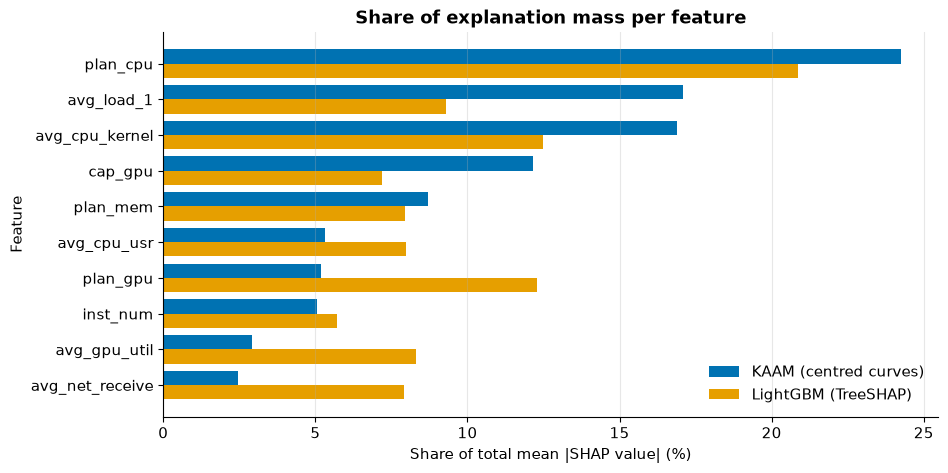

Takeaway: the two explanations rank the ten features with a Spearman correlation of 0.55. Both put the most weight on `plan_cpu`. The largest difference is `avg_load_1` (17% of KAAM's explanation mass against 9% of LightGBM's). A similar ranking can hide different shapes, which the next plots show.

In [7]:
idx = np.random.default_rng(SEED + 1).choice(len(test_np), min(N_EXPLAIN, len(test_np)), replace=False)
X_exp = X["test"].iloc[idx]
d_exp = design(X_exp.to_numpy(), knots)
centre = kaam_contributions(kaam, D["train"]).mean(axis=0)
kaam_sv = kaam_contributions(kaam, d_exp) - centre
contrib = lgbm.predict(X_exp, num_iteration=lgbm.best_iteration, pred_contrib=True)
lgbm_sv = contrib[:, :-1]

imp = pd.DataFrame({"KAAM": np.abs(kaam_sv).mean(0), "LightGBM": np.abs(lgbm_sv).mean(0)}, index=FEATURES)
share = imp / imp.sum()
rank_corr = share.rank().corr(method="spearman").iloc[0, 1]


def plot_importance_pair(ax, share):
    """Side-by-side bars of each feature's share of total mean |SHAP value|."""
    share = share.sort_values("KAAM")
    yy = np.arange(len(share))
    ax.barh(yy + 0.2, share["KAAM"] * 100, 0.4, color=BLUE, label="KAAM (centred curves)")
    ax.barh(yy - 0.2, share["LightGBM"] * 100, 0.4, color=ORANGE, label="LightGBM (TreeSHAP)")
    ax.set_yticks(yy, share.index)
    ax.set_title("Share of explanation mass per feature")
    ax.set_xlabel("Share of total mean |SHAP value| (%)")
    ax.set_ylabel("Feature")
    ax.legend(loc="lower right")
    ax.grid(axis="y", visible=False)


display((share * 100).round(1).sort_values("KAAM", ascending=False))
fig, ax = plt.subplots(figsize=(10, 5))
plot_importance_pair(ax, share)
plt.show()
top_k, top_l = share["KAAM"].idxmax(), share["LightGBM"].idxmax()
top_text = (f"Both put the most weight on `{top_k}`" if top_k == top_l
            else f"KAAM puts the most weight on `{top_k}` and LightGBM on `{top_l}`")
biggest_gap = (share["LightGBM"] - share["KAAM"]).abs().idxmax()
say(f"Takeaway: the two explanations rank the ten features with a Spearman correlation of {rank_corr:.2f}. "
    f"{top_text}. The largest difference is `{biggest_gap}` ({share.loc[biggest_gap, 'KAAM']:.0%} of KAAM's "
    f"explanation mass against {share.loc[biggest_gap, 'LightGBM']:.0%} of LightGBM's). A similar ranking can hide "
    "different shapes, which the next plots show.")

## 4. Curves against SHAP dependence plots

Each panel shows LightGBM's SHAP value for one feature on each explained task (dots) and KAAM's centred curve for
the same feature (line), both in log-odds. Where the dots scatter vertically at one x value, LightGBM's
contribution depends on other features, which an additive model cannot express.

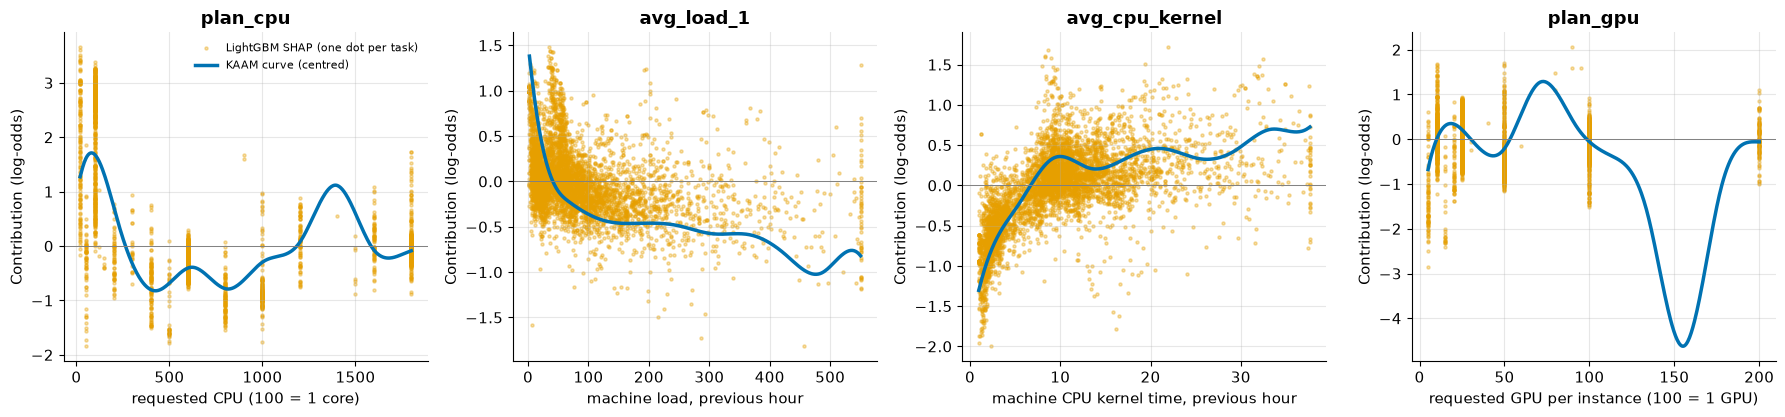

LightGBM SHAP spread at a fixed feature value (log-odds): {'plan_gpu': 0.405, 'plan_cpu': 0.347, 'avg_load_1': 0.262, 'avg_cpu_kernel': 0.251, 'avg_net_receive': 0.233, 'avg_gpu_util': 0.228, 'avg_cpu_usr': 0.217, 'inst_num': 0.195, 'plan_mem': 0.141, 'cap_gpu': 0.085}


Takeaway: for the telemetry features the curves follow the centre of LightGBM's clouds, so the two models agree on the direction of those effects. LightGBM's SHAP values spread most at a fixed value for `plan_gpu` (0.41 log-odds), where its prediction depends on the other features as well. Between observed request values (for example `plan_gpu` from 100 to 200) the KAAM curve has no data under it, so its swings there have no counterpart in LightGBM.

In [8]:
def plot_curve_vs_shap(ax, f, kaam, scaler, X_exp, lgbm_sv, centre, legend=True):
    """LightGBM SHAP dependence scatter with the KAAM centred curve on top, in raw units."""
    j = FEATURES.index(f)
    raw = scaler.to_raw(f, X_exp[f].to_numpy())
    ax.scatter(raw, lgbm_sv[:, j], s=5, alpha=0.35, color=ORANGE, rasterized=True, label="LightGBM SHAP (one dot per task)")
    g = np.linspace(0, 1, 400)
    ax.plot(scaler.to_raw(f, g), shape_curve(kaam, f, g) - centre[j], color=BLUE, lw=2.5, label="KAAM curve (centred)")
    ax.axhline(0, color="grey", lw=0.7)
    ax.set_title(f"{f}")
    ax.set_xlabel(FEATURE_NOTES[f])
    ax.set_ylabel("Contribution (log-odds)")
    if legend:
        ax.legend(fontsize=8, loc="upper right")


top4 = list(share.max(axis=1).sort_values(ascending=False).index[:4])
fig, axes = plt.subplots(1, 4, figsize=(18, 4.3))
for k, (ax, f) in enumerate(zip(axes, top4)):
    plot_curve_vs_shap(ax, f, kaam, scaler, X_exp, lgbm_sv, centre, legend=(k == 0))
plt.tight_layout()
plt.show()


def vertical_spread(f, X_exp, lgbm_sv):
    """Mean within-value standard deviation of LightGBM SHAP for one feature (0 for a purely additive effect)."""
    j = FEATURES.index(f)
    s = pd.DataFrame({"x": X_exp[f].round(4).to_numpy(), "sv": lgbm_sv[:, j]})
    g = s.groupby("x")["sv"].agg(["std", "size"]).dropna()
    return float(np.average(g["std"], weights=g["size"])) if len(g) else np.nan


spread = pd.Series({f: vertical_spread(f, X_exp, lgbm_sv) for f in FEATURES}).sort_values(ascending=False)
print("LightGBM SHAP spread at a fixed feature value (log-odds):", spread.round(3).to_dict())
say(f"Takeaway: for the telemetry features the curves follow the centre of LightGBM's clouds, so the two models "
    f"agree on the direction of those effects. LightGBM's SHAP values spread most at a fixed value for "
    f"`{spread.index[0]}` ({spread.iloc[0]:.2f} log-odds), where its prediction depends on the other features as "
    "well. Between observed request values (for example `plan_gpu` from 100 to 200) the KAAM curve has no data under "
    "it, so its swings there have no counterpart in LightGBM.")

## 5. Task by task: how often do the explanations agree?

For each explained task we compare the ten KAAM contributions with the ten LightGBM SHAP values: the rank
correlation across features, and whether both name the same feature as the largest push toward or away from
failure.

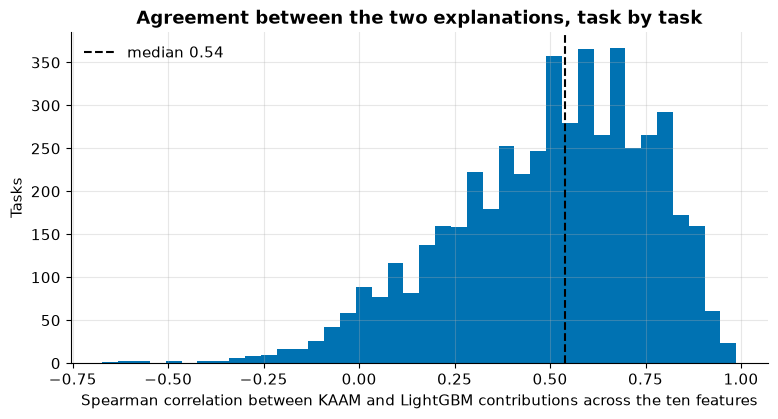

Takeaway: the median task-level rank correlation is 0.54, and the two methods name the same top feature with the same sign for 39% of tasks. For a single task, two accurate models can tell different stories, so a per-task explanation tells you about the model that produced it.

In [9]:
from scipy.stats import spearmanr

per_task_rho = np.array([spearmanr(a, b).statistic for a, b in zip(kaam_sv, lgbm_sv)])
same_top = (np.abs(kaam_sv).argmax(1) == np.abs(lgbm_sv).argmax(1))
same_sign_top = same_top & (np.sign(kaam_sv[np.arange(len(kaam_sv)), np.abs(kaam_sv).argmax(1)])
                            == np.sign(lgbm_sv[np.arange(len(lgbm_sv)), np.abs(lgbm_sv).argmax(1)]))
fig, ax = plt.subplots(figsize=(9, 4.3))
ax.hist(per_task_rho[np.isfinite(per_task_rho)], bins=40, color=BLUE)
ax.axvline(np.nanmedian(per_task_rho), color=BLACK, ls="--", label=f"median {np.nanmedian(per_task_rho):.2f}")
ax.set_title("Agreement between the two explanations, task by task")
ax.set_xlabel("Spearman correlation between KAAM and LightGBM contributions across the ten features")
ax.set_ylabel("Tasks")
ax.legend()
plt.show()
say(f"Takeaway: the median task-level rank correlation is {np.nanmedian(per_task_rho):.2f}, and the two methods name "
    f"the same top feature with the same sign for {same_sign_top.mean():.0%} of tasks. For a single task, two "
    "accurate models can tell different stories, so a per-task explanation tells you about the model that produced it.")

## 6. Three tasks explained both ways

One task both models call risky, one where they disagree most about the risk, and one both call safe.

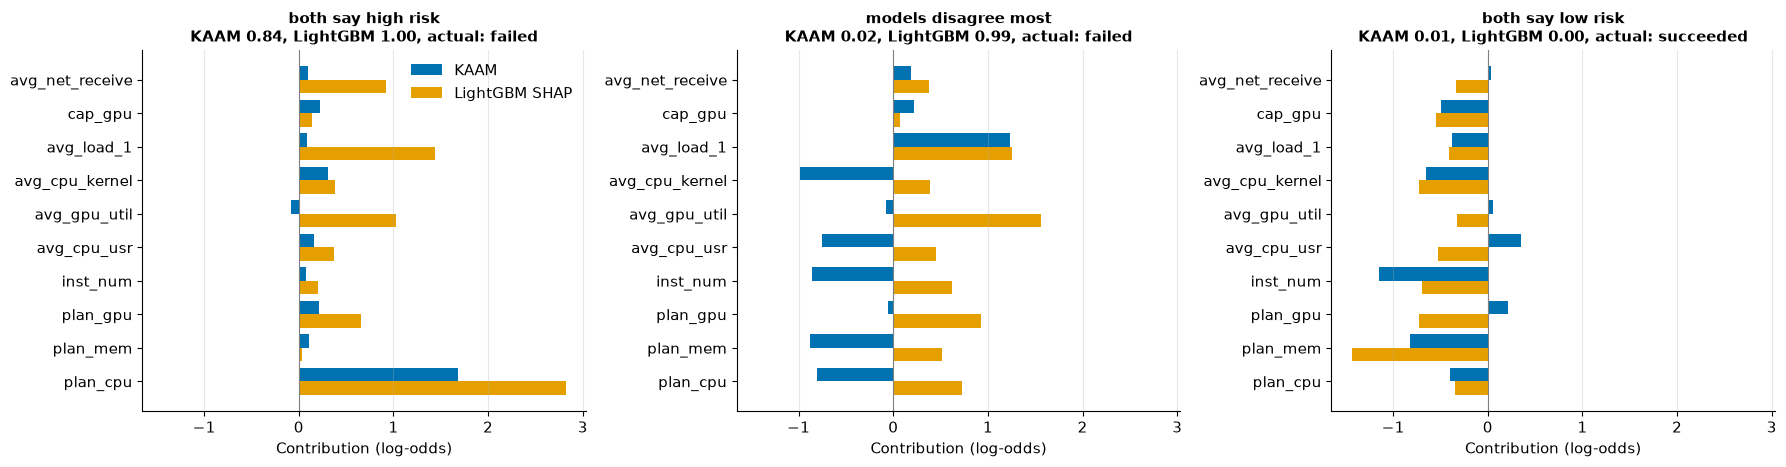

raw features of the task the models disagree on most:
{'plan_cpu': 400.0, 'plan_mem': 5.86, 'plan_gpu': 100.0, 'inst_num': 10.0, 'avg_cpu_usr': 2.68, 'avg_gpu_util': 202.62, 'avg_cpu_kernel': 1.77, 'avg_load_1': 4.71, 'cap_gpu': 8.0, 'avg_net_receive': 18500855.75}


Takeaway: on the clear cases both explanations point at the same few features. Where the models disagree, the KAAM bars can be checked against its curves directly, while the LightGBM bars depend on combinations of features that no single plot shows.

In [10]:
pk = p_kaam[idx]
pl = p_lgbm[idx]
cases = {"both say high risk": int(np.argmax(pk + pl)),
         "models disagree most": int(np.argmax(np.abs(pk - pl))),
         "both say low risk": int(np.argmin(pk + pl))}
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8), sharex=True)
yy = np.arange(len(FEATURES))
for ax, (name, i) in zip(axes, cases.items()):
    ax.barh(yy + 0.2, kaam_sv[i], 0.4, color=BLUE, label="KAAM")
    ax.barh(yy - 0.2, lgbm_sv[i], 0.4, color=ORANGE, label="LightGBM SHAP")
    ax.set_yticks(yy, FEATURES)
    ax.axvline(0, color="grey", lw=0.8)
    true = Y["test"][idx[i]]
    ax.set_title(f"{name}\nKAAM {pk[i]:.2f}, LightGBM {pl[i]:.2f}, actual: {'failed' if true else 'succeeded'}",
                 fontsize=11)
    ax.set_xlabel("Contribution (log-odds)")
    ax.grid(axis="y", visible=False)
axes[0].legend(loc="upper right")
plt.tight_layout()
plt.show()
d = cases["models disagree most"]
raw_case = tasks.loc[split["test"][idx[d]], FEATURES]
print("raw features of the task the models disagree on most:")
print(raw_case.round(2).to_dict())
say("Takeaway: on the clear cases both explanations point at the same few features. Where the models disagree, "
    "the KAAM bars can be checked against its curves directly, while the LightGBM bars depend on combinations of "
    "features that no single plot shows.")

## 7. Following one curve: the one-core rule and user 1

KAAM's `plan_cpu` curve has a sharp rise at the smallest CPU requests. A curve you can read invites a question:
who are the tasks behind that shape? The trace's most active user (`user_rank` 1) submits about a third of all tasks,
and many of them ask for exactly one CPU core (`plan_cpu` = 100).

tasks                    failure_rate                   
request         one core other CPU requests     one core other CPU requests
who                                                                        
all other users    13996             358458        0.208              0.179
user 1             63034             104328        0.872              0.247

KAAM without user 1: test ROC-AUC 0.703 on 55,869 test tasks


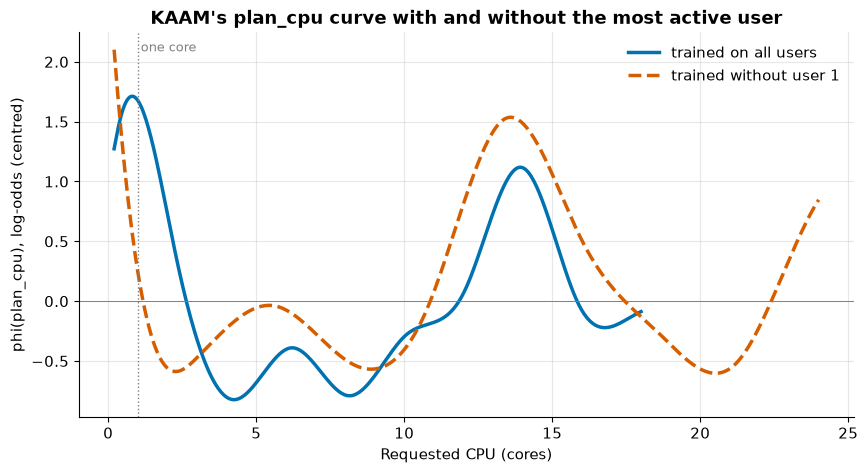

Takeaway: user 1's one-core tasks fail 87% of the time, while other users' one-core tasks fail 21%, close to their 18% for other requests. Trained on all users, KAAM adds +1.68 log-odds for a one-core request; trained without user 1 it adds +0.25. The bump at one core describes one user's jobs, which a random split rewards and a new user would not share. The model without user 1 learns its own steep rise for requests below one core, so each curve should be read with the users behind it in mind.

In [11]:
def one_core_table(tasks):
    """Failure rate and task count for one-core vs other requests, for user 1 and for everyone else."""
    t = tasks.assign(who=np.where(tasks["user_rank"] == 1, "user 1", "all other users"),
                     request=np.where(tasks["plan_cpu"] == ONE_CORE, "one core", "other CPU requests"))
    return t.groupby(["who", "request"])["label"].agg(tasks="size", failure_rate="mean").unstack("request")


ot = one_core_table(tasks)
display(ot.round(3))

keep = np.flatnonzero(users != 1)
split_wo = {k: keep[v] for k, v in random_split(y[keep]).items()}
sc_wo = Scaler().fit(tasks.loc[split_wo["train"], FEATURES])
X_wo = {k: sc_wo.transform(tasks.loc[ix, FEATURES]) for k, ix in split_wo.items()}
D_wo = {k: design(X_wo[k].to_numpy(), knots) for k in X_wo}
kaam_wo, hist_wo = fit_kaam(D_wo["train"], y[split_wo["train"]], D_wo["val"], y[split_wo["val"]], best_lam)
auc_wo = roc_auc_score(y[split_wo["test"]], kaam_logit(kaam_wo, D_wo["test"]))
print(f"KAAM without user 1: test ROC-AUC {auc_wo:.3f} on {len(split_wo['test']):,} test tasks")


def plot_plan_cpu(ax, kaam, scaler, centre_all, kaam_wo, sc_wo, D_wo_train):
    """KAAM plan_cpu curve trained with all users vs without user 1, centred, in CPU cores."""
    j = FEATURES.index("plan_cpu")
    g = np.linspace(0, 1, 400)
    ax.plot(scaler.to_raw("plan_cpu", g) / 100, shape_curve(kaam, "plan_cpu", g) - centre_all[j], color=BLUE, lw=2.5,
            label="trained on all users")
    c_wo = kaam_contributions(kaam_wo, D_wo_train).mean(axis=0)[j]
    ax.plot(sc_wo.to_raw("plan_cpu", g) / 100, shape_curve(kaam_wo, "plan_cpu", g) - c_wo, color=VERMILLION, lw=2.5,
            ls="--", label="trained without user 1")
    ax.axvline(1, color="grey", ls=":", lw=1)
    ax.text(1.1, 0.95, "one core", color="grey", fontsize=9, transform=ax.get_xaxis_transform())
    ax.axhline(0, color="grey", lw=0.7)
    ax.set_title("KAAM's plan_cpu curve with and without the most active user")
    ax.set_xlabel("Requested CPU (cores)")
    ax.set_ylabel("phi(plan_cpu), log-odds (centred)")
    ax.legend()


fig, ax = plt.subplots(figsize=(10, 5))
plot_plan_cpu(ax, kaam, scaler, centre, kaam_wo, sc_wo, D_wo["train"])
plt.show()
j = FEATURES.index("plan_cpu")
g1 = scaler.to_scaled("plan_cpu", ONE_CORE)
g1_wo = sc_wo.to_scaled("plan_cpu", ONE_CORE)
phi1_all = float(shape_curve(kaam, "plan_cpu", [g1])[0] - centre[j])
phi1_wo = float(shape_curve(kaam_wo, "plan_cpu", [g1_wo])[0] - kaam_contributions(kaam_wo, D_wo["train"]).mean(0)[j])
u1_one = ot.loc["user 1", ("failure_rate", "one core")]
oth_one = ot.loc["all other users", ("failure_rate", "one core")]
oth_rest = ot.loc["all other users", ("failure_rate", "other CPU requests")]
say(f"Takeaway: user 1's one-core tasks fail {u1_one:.0%} of the time, while other users' one-core tasks fail "
    f"{oth_one:.0%}, close to their {oth_rest:.0%} for other requests. Trained on all users, KAAM adds "
    f"{phi1_all:+.2f} log-odds for a one-core request; trained without user 1 it adds {phi1_wo:+.2f}. The bump at "
    "one core describes one user's jobs, which a random split rewards and a new user would not share. The model "
    "without user 1 learns its own steep rise for requests below one core, so each curve should be read with the "
    "users behind it in mind.")

In [12]:
def draw_cover(ax):
    plot_curve_vs_shap(ax, "plan_cpu", kaam, scaler, X_exp, lgbm_sv, centre)
    ax.set_title("plan_cpu: KAAM's curve over LightGBM's SHAP values on the same test tasks")


save_cover(draw_cover)
print("saved cover.png (plan_cpu: KAAM curve over LightGBM SHAP values)")

saved cover.png (plan_cpu: KAAM curve over LightGBM SHAP values)


## 8. What we found

In [13]:
say(f"""- For an additive model, SHAP values are the centred curve values: brute-force Shapley values over all 1,024
  feature subsets match KAAM's centred contributions to within {np.abs(brute - closed_form).max():.0e} log-odds.
- On the same {len(idx):,} test tasks, KAAM and LightGBM rank the features with a Spearman correlation of
  {rank_corr:.2f}, but agree on the top feature (with its sign) for only {same_sign_top.mean():.0%} of tasks.
- LightGBM scores higher on the random split ({scores.loc['LightGBM', 'test ROC-AUC']:.3f} against
  {scores.loc['KAAM', 'test ROC-AUC']:.3f}), partly through interactions that no one-dimensional plot shows.
- KAAM's sharpest curve, the rise at one CPU core, comes from user 1: its one-core tasks fail {u1_one:.0%} of the
  time against {oth_one:.0%} for everyone else, and the effect shrinks from {phi1_all:+.2f} to {phi1_wo:+.2f}
  log-odds when that user is removed.""")

- For an additive model, SHAP values are the centred curve values: brute-force Shapley values over all 1,024
  feature subsets match KAAM's centred contributions to within 2e-07 log-odds.
- On the same 5,000 test tasks, KAAM and LightGBM rank the features with a Spearman correlation of
  0.55, but agree on the top feature (with its sign) for only 39% of tasks.
- LightGBM scores higher on the random split (0.900 against
  0.766), partly through interactions that no one-dimensional plot shows.
- KAAM's sharpest curve, the rise at one CPU core, comes from user 1: its one-core tasks fail 87% of the
  time against 21% for everyone else, and the effect shrinks from +1.68 to +0.25
  log-odds when that user is removed.

### Limitations

- TreeSHAP for LightGBM uses the tree path distribution as background, while KAAM is centred on training tasks;
  the two choices are close and can differ in detail.
- One seed and one split; the KANVAS paper repeats the comparison over five splits and with users held out.
- An additive model can only show what it can represent. Where LightGBM's SHAP values spread at a fixed feature
  value, the KAAM curve shows only the average effect.

### Ideas to try

- Compare interventional SHAP for LightGBM (`shap.TreeExplainer` with a background set) against the path-dependent
  values used here.
- Drop user 1 from training and test, and redo sections 3 to 5 to see whether the two explanations converge.
- Fit an EBM (`interpret` package) and add its shape functions as a third view.

### The series

1. [Alibaba PAI GPU trace 2020: a complete EDA](https://www.kaggle.com/code/swapnilshukla007/alibaba-pai-gpu-trace-2020-a-complete-eda)
2. [Where cluster GPUs sit idle: utilization, over-requesting and fragmentation](https://www.kaggle.com/code/swapnilshukla007/where-cluster-gpus-sit-idle)
3. [Predicting GPU task failure: a LightGBM baseline explained with SHAP](https://www.kaggle.com/code/swapnilshukla007/predicting-gpu-task-failure-lightgbm-and-shap)
4. [Kolmogorov-Arnold additive models from scratch: B-spline edge functions in PyTorch](https://www.kaggle.com/code/swapnilshukla007/kolmogorov-arnold-additive-models-from-scratch)
5. Reading the splines: KAAM shape functions vs SHAP on the same tasks (this notebook)

If something here is wrong or unclear, a comment helps more than anything; an upvote helps others find it.